In [49]:
import os
import numpy as np
import pandas as pd
import seaborn as sb
import PcmPy as pcm
import matplotlib.pyplot as plt
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.util as util
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.models as models
import EFC_learningfMRI.G_matrix as mat

In [50]:
H     = 'L'
atlas = 'ROI'
rois  = gl.rois[atlas]
glm   = 3

model_corr = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'model_correlation.within_session.{atlas}.glm{glm}.tsv'), sep='\t')

# one colour per model, shared by every plot below; names are the keys of models.make_G_dict
comp_names = ['type', 'trained', 'untrained', 'mean deviation', 'single finger', 'muscle pattern', 'hand use',]
#chord_models = [c for c in comp_names if c not in ('type', 'trained', 'untrained')]   # properties of the chords themselves
palette = {'type': 'green',
           'identity': 'grey', 
           'trained': 'red', 
           'untrained': 'blue',
           'single finger': 'purple', 
           'muscle pattern': 'brown', 
           'hand use': 'pink',
           #'signed force pattern': 'green',
           'mean deviation': 'black', 
           #'flexion-extension bias': 'teal', 
           #'mean force magnitude': 'gold'
           }

# Representational models

What each model predicts about the distances between BOLD activity patterns:

- **identity**: BOLD activity patterns are equally distant in voxel space.
- **single finger**: The distance between BOLD activity patterns for each chord reflects the distance between the patterns obtained by summing the activity patterns evoked by the flexion or extension of each individual finger involved in the chord, measured in the same ROI in a separate dataset (Arbuckle et al., 2020).
- **muscle pattern**: The distance between BOLD activity patterns reflects the distance between the corresponding muscle activity patterns recorded with EMG outside of the MRI scanner in a separate group of participants.
- **hand use**: Chords requiring finger movements that frequently co-occur in everyday hand use evoke similar BOLD activity patterns, based on kinematic recordings (CyberGlove) of everyday hand activities (Ingram et al., 2008).
- **mean deviation**: The distance between BOLD activity patterns reflects differences in chord difficulty, as indexed by the mean deviation of the finger forces from the ideal straight force trajectory in session 4 (i.e., last session before training started).
- **trained** / **untrained**: The BOLD activity patterns of the trained or untrained chords, respectively, are more distinct from each other and from the remaining chords than predicted by the other models.
- **type**: Every trained chord is equally far from every untrained chord, and two chords from the same set (both trained or both untrained) have zero distance.

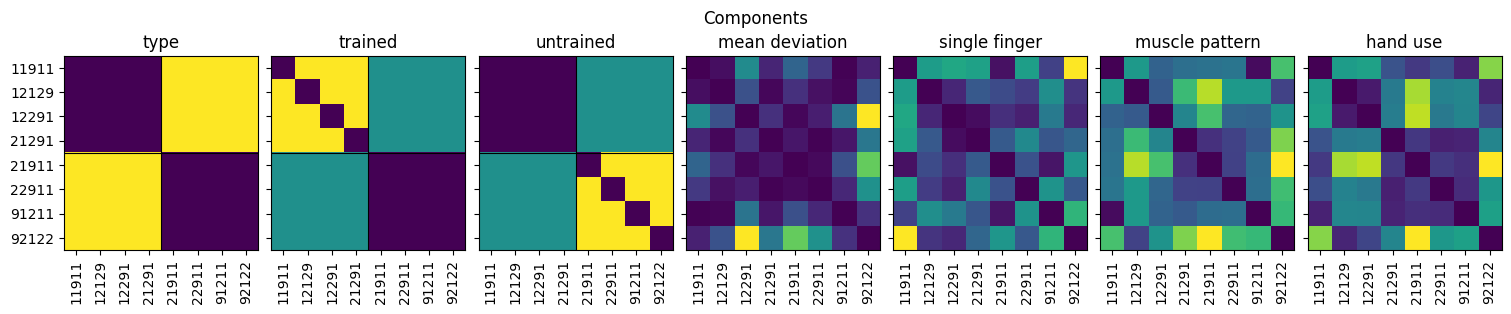

In [ ]:
sn = 104
M  = models.make_models(sn, glm=glm, Hem=H, roi=rois[0], comp_names=comp_names)
Mc = M[-2]

chords = np.array(util.get_trained_and_untrained(sn)).astype(int)   # the participant's trained-first order, the order of Mc.Gc

# two rows of 7; no sharex/sharey: shared axes share the tick formatter, so set_xticklabels on one
# panel would relabel all of them, and the panels use two different chord orders
ncols    = 7
nrows    = int(np.ceil(len(comp_names) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(15, 3), constrained_layout=True, sharex=True, sharey=True)
axs      = axs.ravel()

for i, (G, name) in enumerate(zip(Mc.Gc, comp_names)):
    ax = axs[i]
    if name in chord_models:
        d     = pcm.G_to_dist(mat.G_sorted(G, sn, order=gl.chordID))   # off the participant's trained-first order, onto gl.chordID
        ticks = gl.chordID
    else:
        d     = pcm.G_to_dist(G)                                            # trained-first: the line splits trained from untrained
        ticks = chords
        ax.axhline(3.5, lw=.8, color='k')
        ax.axvline(3.5, lw=.8, color='k')
    ax.imshow(d)
    ax.set_xticks(np.arange(8))
    ax.set_xticklabels(ticks, rotation=90)
    ax.set_yticks(np.arange(8))
    ax.set_yticklabels(ticks)
    ax.set_title(name)

for ax in axs[len(comp_names):]:                                            # hide unused panels if comp_names isn't a multiple of 7
    ax.set_visible(False)

fig.suptitle('Representational models')

fig.savefig(os.path.join(gl.figDir, 'components.pdf'))

plt.show()

condition number of R: 13.9
                 VIF  R2 from others
mean deviation  1.15            0.13
single finger   1.17            0.15
muscle pattern  3.62            0.72
hand use        3.62            0.72


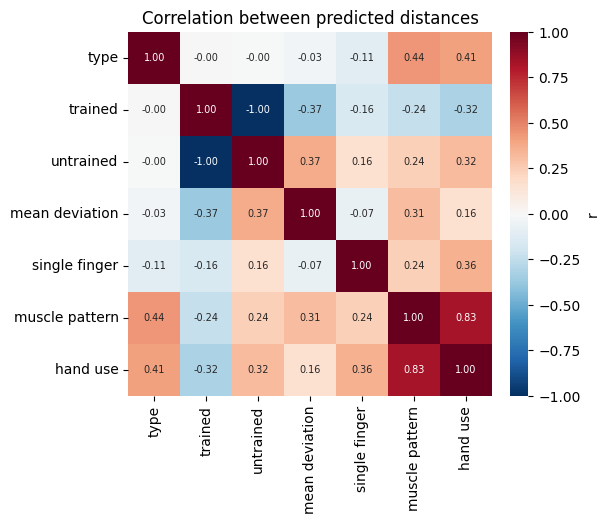

In [52]:
# correlation between the distances predicted by each component (upper triangle of the distance matrix)
# identity predicts the same distance for every pair, so it has no correlation and is left out
names = [n for n in comp_names if n != 'identity']
iu    = np.triu_indices(Mc.Gc.shape[1], k=1)
D     = pcm.G_to_dist(Mc.Gc[[comp_names.index(n) for n in names]])
R     = np.corrcoef(np.array([d[iu] for d in D]))

# condition number: one number for the whole set, large when some combination of components is close to another
# VIF = diag(inv(R)) says which component it is: R2 = 1 - 1/VIF is how well the others predict it
# over the chord models only: trained and untrained distances add up to a constant (r = -1), so R would be singular
chord = [i for i, n in enumerate(names) if n not in ('type', 'trained', 'untrained')]
Rc    = R[np.ix_(chord, chord)]
print(f'condition number of R: {np.linalg.cond(Rc):.1f}')
vif = pd.DataFrame({'VIF': np.diag(np.linalg.inv(Rc))}, index=[names[i] for i in chord])
vif['R2 from others'] = 1 - 1 / vif.VIF
print(vif.round(2))

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

sb.heatmap(pd.DataFrame(R, index=names, columns=names), ax=ax, vmin=-1, vmax=1, cmap='RdBu_r', annot=True, fmt='.2f', annot_kws={'size': 7}, square=True, cbar_kws={'label': 'r', 'fraction': .05})

ax.set_title('Correlation between predicted distances')

plt.show()

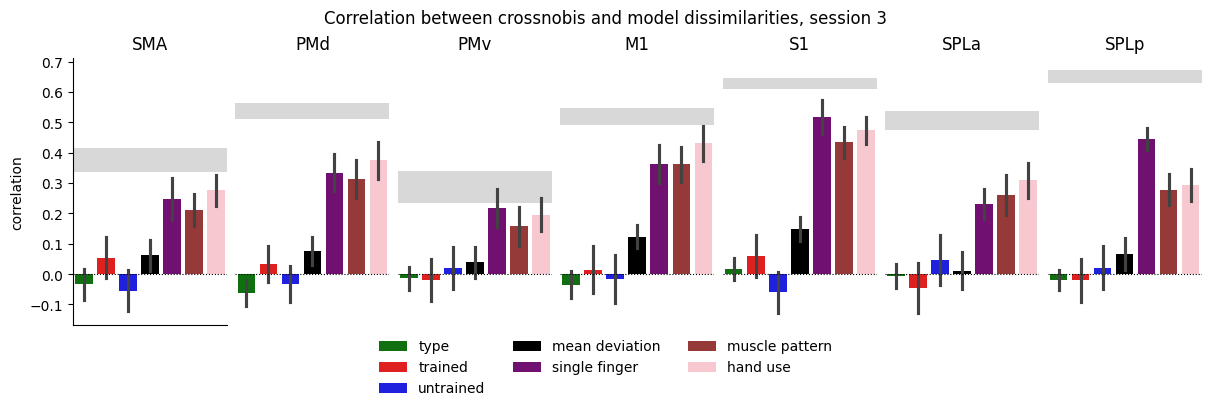

In [53]:
# session 3 only
df = model_corr[(model_corr.Hem == H) & (model_corr.session == 3) & (model_corr.model.isin(comp_names))]

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(12, 4), constrained_layout=True)

vis.plot_im_sess(fig, axs, df, rois, y='r', x='model', hue='model', hue_order=comp_names, palette=palette, kind='bar', native_scale=False, add_zero=True)
vis.add_noise_ceiling(axs, df, rois)
for ax in axs:
    ax.tick_params(bottom=False, labelbottom=False)
axs[0].set_ylabel('correlation')
axs[-1].legend([], frameon=False)
fig.legend(frameon=False, loc='outside lower center', ncol=3)

fig.suptitle('Correlation between crossnobis and model dissimilarities, session 3')

plt.show()

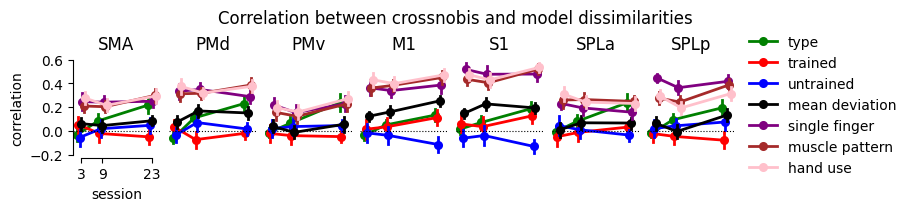

In [54]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, model_corr[model_corr.Hem == H], rois, y='r', x='session', hue='model',
                 hue_order=comp_names, palette=palette, kind='point', dodge=.4, add_zero=True)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('correlation')
axs[0].set_xlabel('session')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='outside right center')

fig.suptitle('Correlation between crossnobis and model dissimilarities')

plt.show()